# Report 4 - Modeling & Validation

Nhánh Regression của ADY201m. M1-M4 là bốn cấu hình trong nhánh này, không phải bốn thuật toán phân loại. Notebook thực thi lại toàn bộ pipeline trên snapshot EDA đóng băng; giữ nguyên notebook phân loại `2_Modeling.ipynb`.

**Kết quả chính của lần chạy 15/11:** hồi quy có liên hệ total-rating âm toàn mẫu, nhưng CI của mẫu ≥20 rating chứa 0 ở cả hai nguồn; khả năng dự báo test rất nhỏ. Các ô dưới tính lại số thực, không chép số vào output.

## 1. Thiết lập và dữ liệu
Chọn Python của `.venv-report4`. Cần các input EDA đã có trong repo; không cần Chrome, MinIO hoặc đăng nhập khi model chạy trên CSV đóng băng.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/modeling/report4.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.modeling import report4 as r
EDA=ROOT/'reports/eda/cross_platform_20261023'
print('Python:',sys.executable)
print('SHA256:', r.sha256(EDA/'harmonized_reviews.csv'))

Python: D:\Code\For Learning\Studing\ADY\ADY201m_Group4_Sentiment-Analysis\.venv-report4\Scripts\python.exe
SHA256: dbf88cea7a8f6d43c754514a1c3dbfb0ebab42c97973217e350bd4d72066b8d8


In [2]:
reviews=pd.read_csv(EDA/'harmonized_reviews.csv',low_memory=False)
r.validate_reviews(reviews)
display(reviews.groupby('source').agg(reviews=('shop','size'),shops=('shop','nunique'),rated=('rating100','count')))

,reviews,shops,rated
source,,,
Foody,132922,5410,132922
Google Maps,147565,1925,146555


## 2. Feature có ý nghĩa gì?
`total` là tổng review hiển thị, khác `n` đã crawl. Target `mean100` là trung bình rating hợp lệ. `mean_log_length` lấy mean(ln(1+L)) trên đúng bộ lọc vừa có rating vừa có chữ. `service100` đã /100. Bắc là mốc tham chiếu.

In [3]:
shops=r.aggregate_shops(reviews).merge(r.length_features(reviews),on=['source','shop'],validate='one_to_one',how='left')
display(shops[['source','n','n_rated','mean100','total','service100','mean_log_length']].head())
valid=reviews.loc[(reviews.rating100.notna())&(reviews.text_chars>0)]
example=valid.loc[valid.source=='Foody'].groupby('shop').filter(lambda x: len(x)>3).groupby('shop').head(4).head(4)
display(example[['rating100','text_chars']].assign(log_length=lambda x:np.log1p(x.text_chars)))

,source,n,n_rated,mean100,total,service100,mean_log_length
0,Foody,1,1,80.0,1.0,80.0,1.098612
1,Foody,1,1,50.0,1.0,50.0,1.386294
2,Foody,1,1,66.0,1.0,60.0,5.556828
3,Foody,2,2,59.0,2.0,60.0,3.346042
4,Foody,1,1,74.0,1.0,70.0,7.418781


,rating100,text_chars,log_length
0,10.0,292,5.680173
1,72.0,548,6.308098
2,54.0,449,6.109248
3,48.0,102,4.634729


## 3. Fit và đối chiếu M1
OLS toàn mẫu và HC1 dùng t, chỉ phục vụ suy luận/đối chiếu. Không dùng fit này để chấm test. Mỗi biến miền là dummy 0/1.

In [4]:
foody=shops.loc[(shops.source=='Foody')&shops.mean100.notna()&(shops.total>0)]
fit=r.fit_ols(foody)
display(pd.DataFrame(r.coefficient_rows(fit,'Foody','M1','mean100'))[['term','estimate','se','ci_low','ci_high','p','n']])

,term,estimate,se,ci_low,ci_high,p,n
0,Intercept,72.575195,0.402255,71.786612,73.363777,0.000000,5410
1,log10_total,-0.958612,0.301651,-1.549970,-0.367255,0.001492,5410
2,region_Trung,-0.704012,1.019878,-2.703385,1.295360,0.490041,5410
3,region_Nam,0.573179,0.438763,-0.286972,1.433331,0.191488,5410


## 4. Chạy đầy đủ M1-M4 và đánh giá
80/20 seed42, phân tầng miền. M1/M2 đánh giá cùng cohort M2; 5-fold CV chỉ train; Dummy fit trung bình train. M3 target phục vụ riêng. M4 demeaned full-sample, SE cụm theo quán. Chạy lại tạo thư mục mới, không ghi đè báo cáo trước.

In [5]:
from datetime import datetime
OUT=ROOT/'report4_outputs'/('notebook_'+datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
r.run(EDA,OUT,42)
manifest=json.loads((OUT/'manifest.json').read_text(encoding='utf-8'))
assert manifest['reference_checks_passed']==62
print('Reference checks:',manifest['reference_checks_passed'])

{
  "output": "D:\\Code\\For Learning\\Studing\\ADY\\ADY201m_Group4_Sentiment-Analysis\\report4_outputs\\notebook_20261115_002350_946462",
  "reference_checks_passed": 62,
  "cohorts": [
    {
      "source": "Foody",
      "review_rows": 132922,
      "all_shops": 5410,
      "m1_shops": 5410,
      "m2_shops": 5410,
      "excluded_no_mean_or_total": 0,
      "excluded_no_valid_text": 0,
      "crawl_exceeds_total": 325
    },
    {
      "source": "Google Maps",
      "review_rows": 147565,
      "all_shops": 1925,
      "m1_shops": 1910,
      "m2_shops": 1901,
      "excluded_no_mean_or_total": 15,
      "excluded_no_valid_text": 9,
      "crawl_exceeds_total": 2
    }
  ]
}
Reference checks: 62


In [6]:
evaluation=pd.read_csv(OUT/'table1_model_evaluation_metrics.csv')
display(evaluation.loc[evaluation.partition=='test',['source','target','model','n','mse','rmse','mae','r2','cv_rmse_mean','selected_by_train_cv']])

,source,target,model,n,mse,rmse,mae,r2,cv_rmse_mean,selected_by_train_cv
1,Foody,mean100,Dummy,1082,251.632968,15.862943,11.135524,-0.000007,14.924736,False
3,Foody,mean100,M1,1082,251.843665,15.869583,11.076209,-0.000844,14.906276,False
5,Foody,mean100,M2,1082,250.333126,15.821919,11.003074,0.005159,14.896905,True
7,Foody,service100,Dummy,1082,327.687071,18.102129,13.149828,-0.000232,17.227074,False
9,Foody,service100,M3,1082,326.983891,18.082696,13.028215,0.001914,17.179782,True
11,Google Maps,mean100,Dummy,381,92.203709,9.602276,7.752306,-0.009542,10.456344,False
13,Google Maps,mean100,M1,381,91.113980,9.545364,7.734822,0.002389,10.440901,True
15,Google Maps,mean100,M2,381,91.299709,9.555088,7.767367,0.000355,10.443993,False


### Kết quả dự báo so với mốc trung bình
RMSE càng nhỏ càng tốt. R² gần 0 cho thấy feature hiện tại dự đoán chưa tốt hơn nhiều so mốc trung bình; hệ số có ý nghĩa thống kê không thay cho chất lượng dự báo.

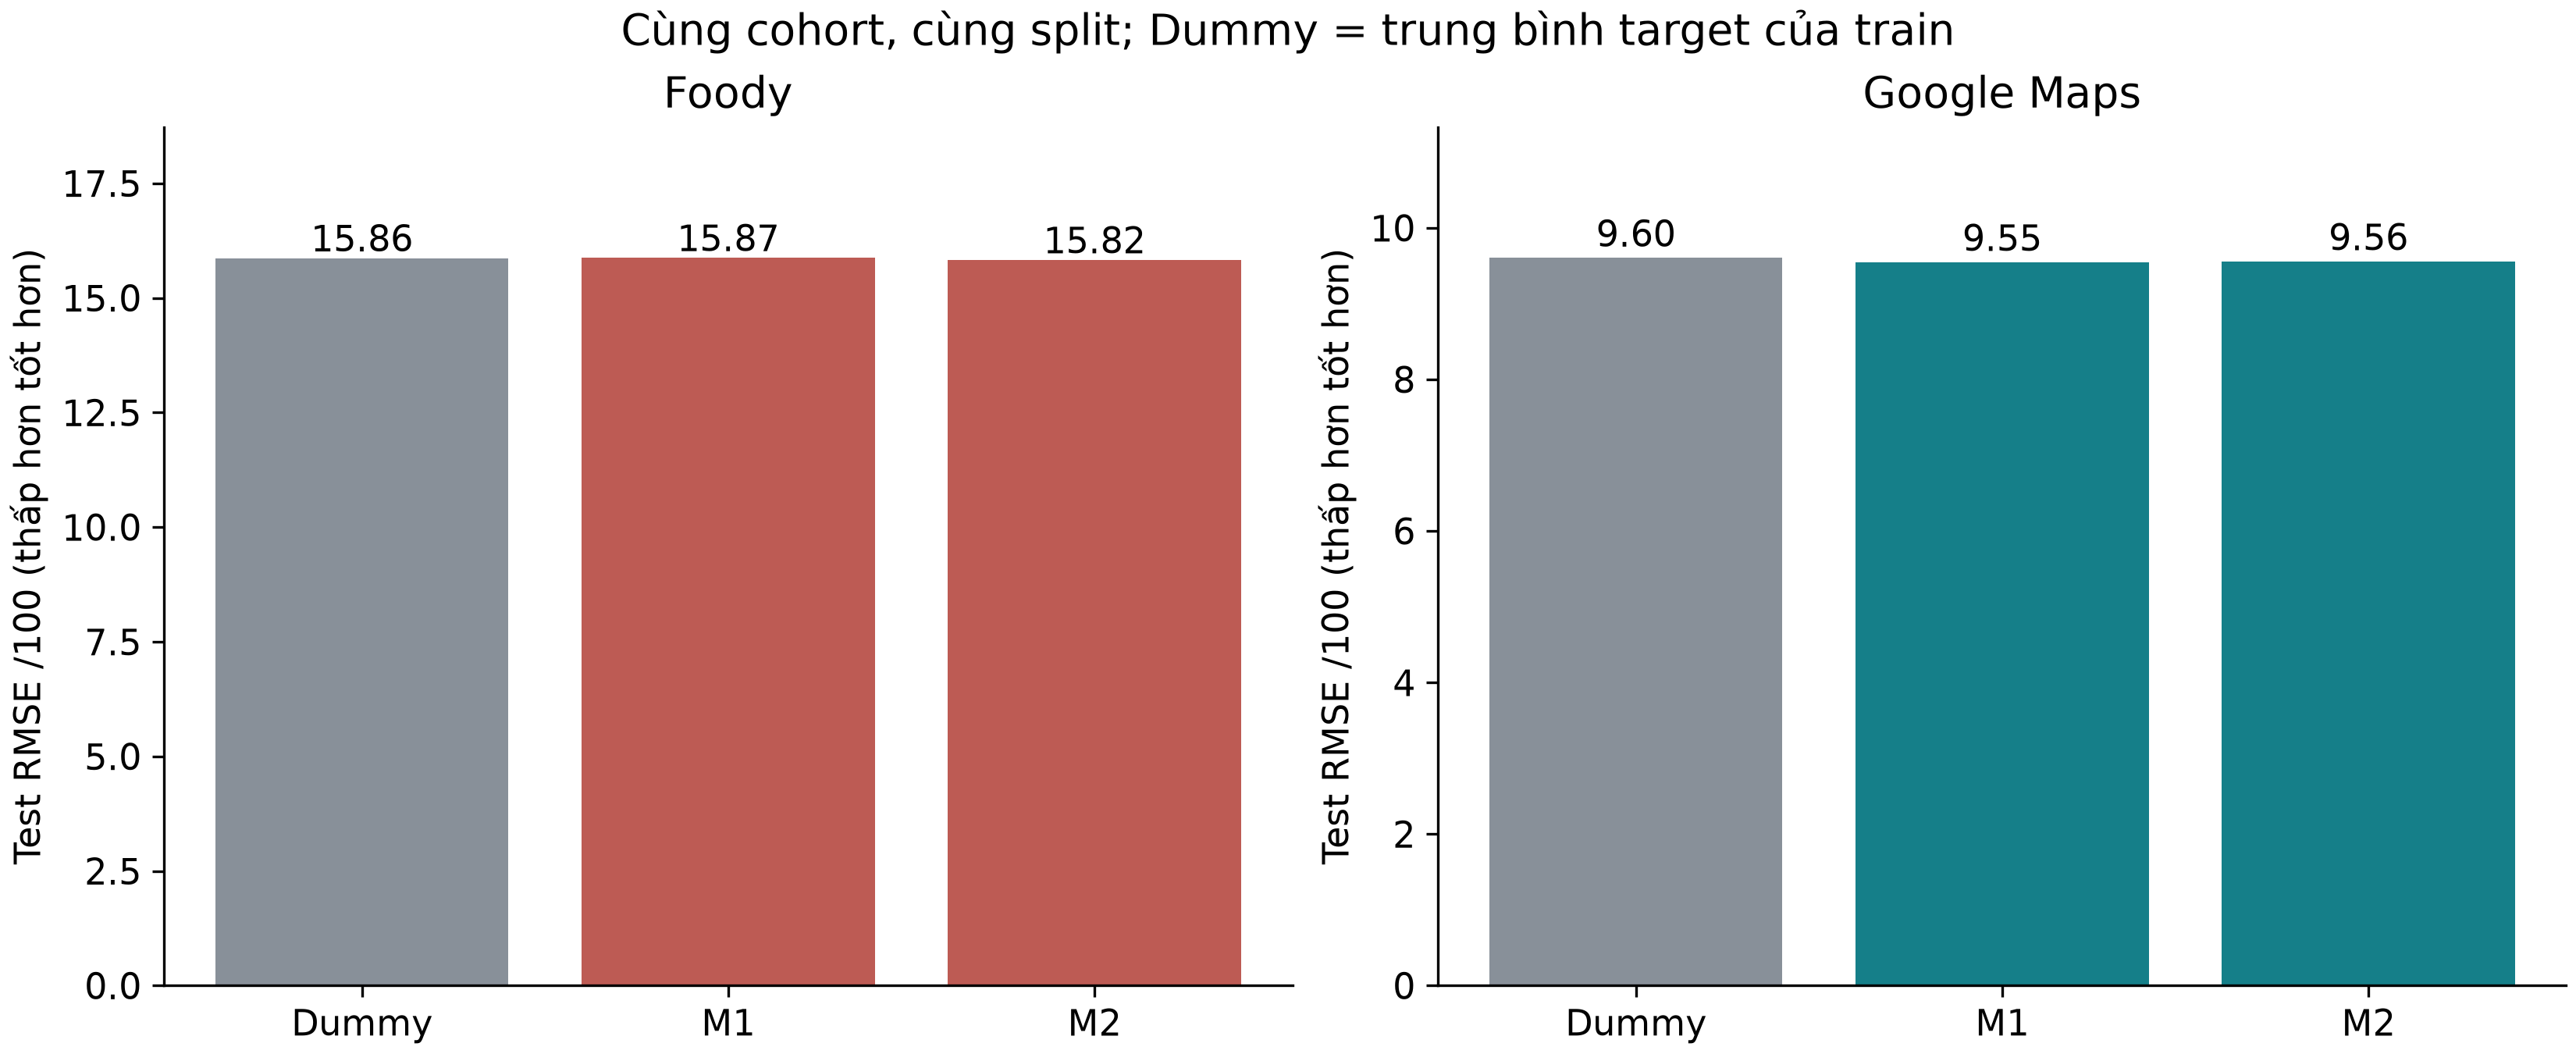

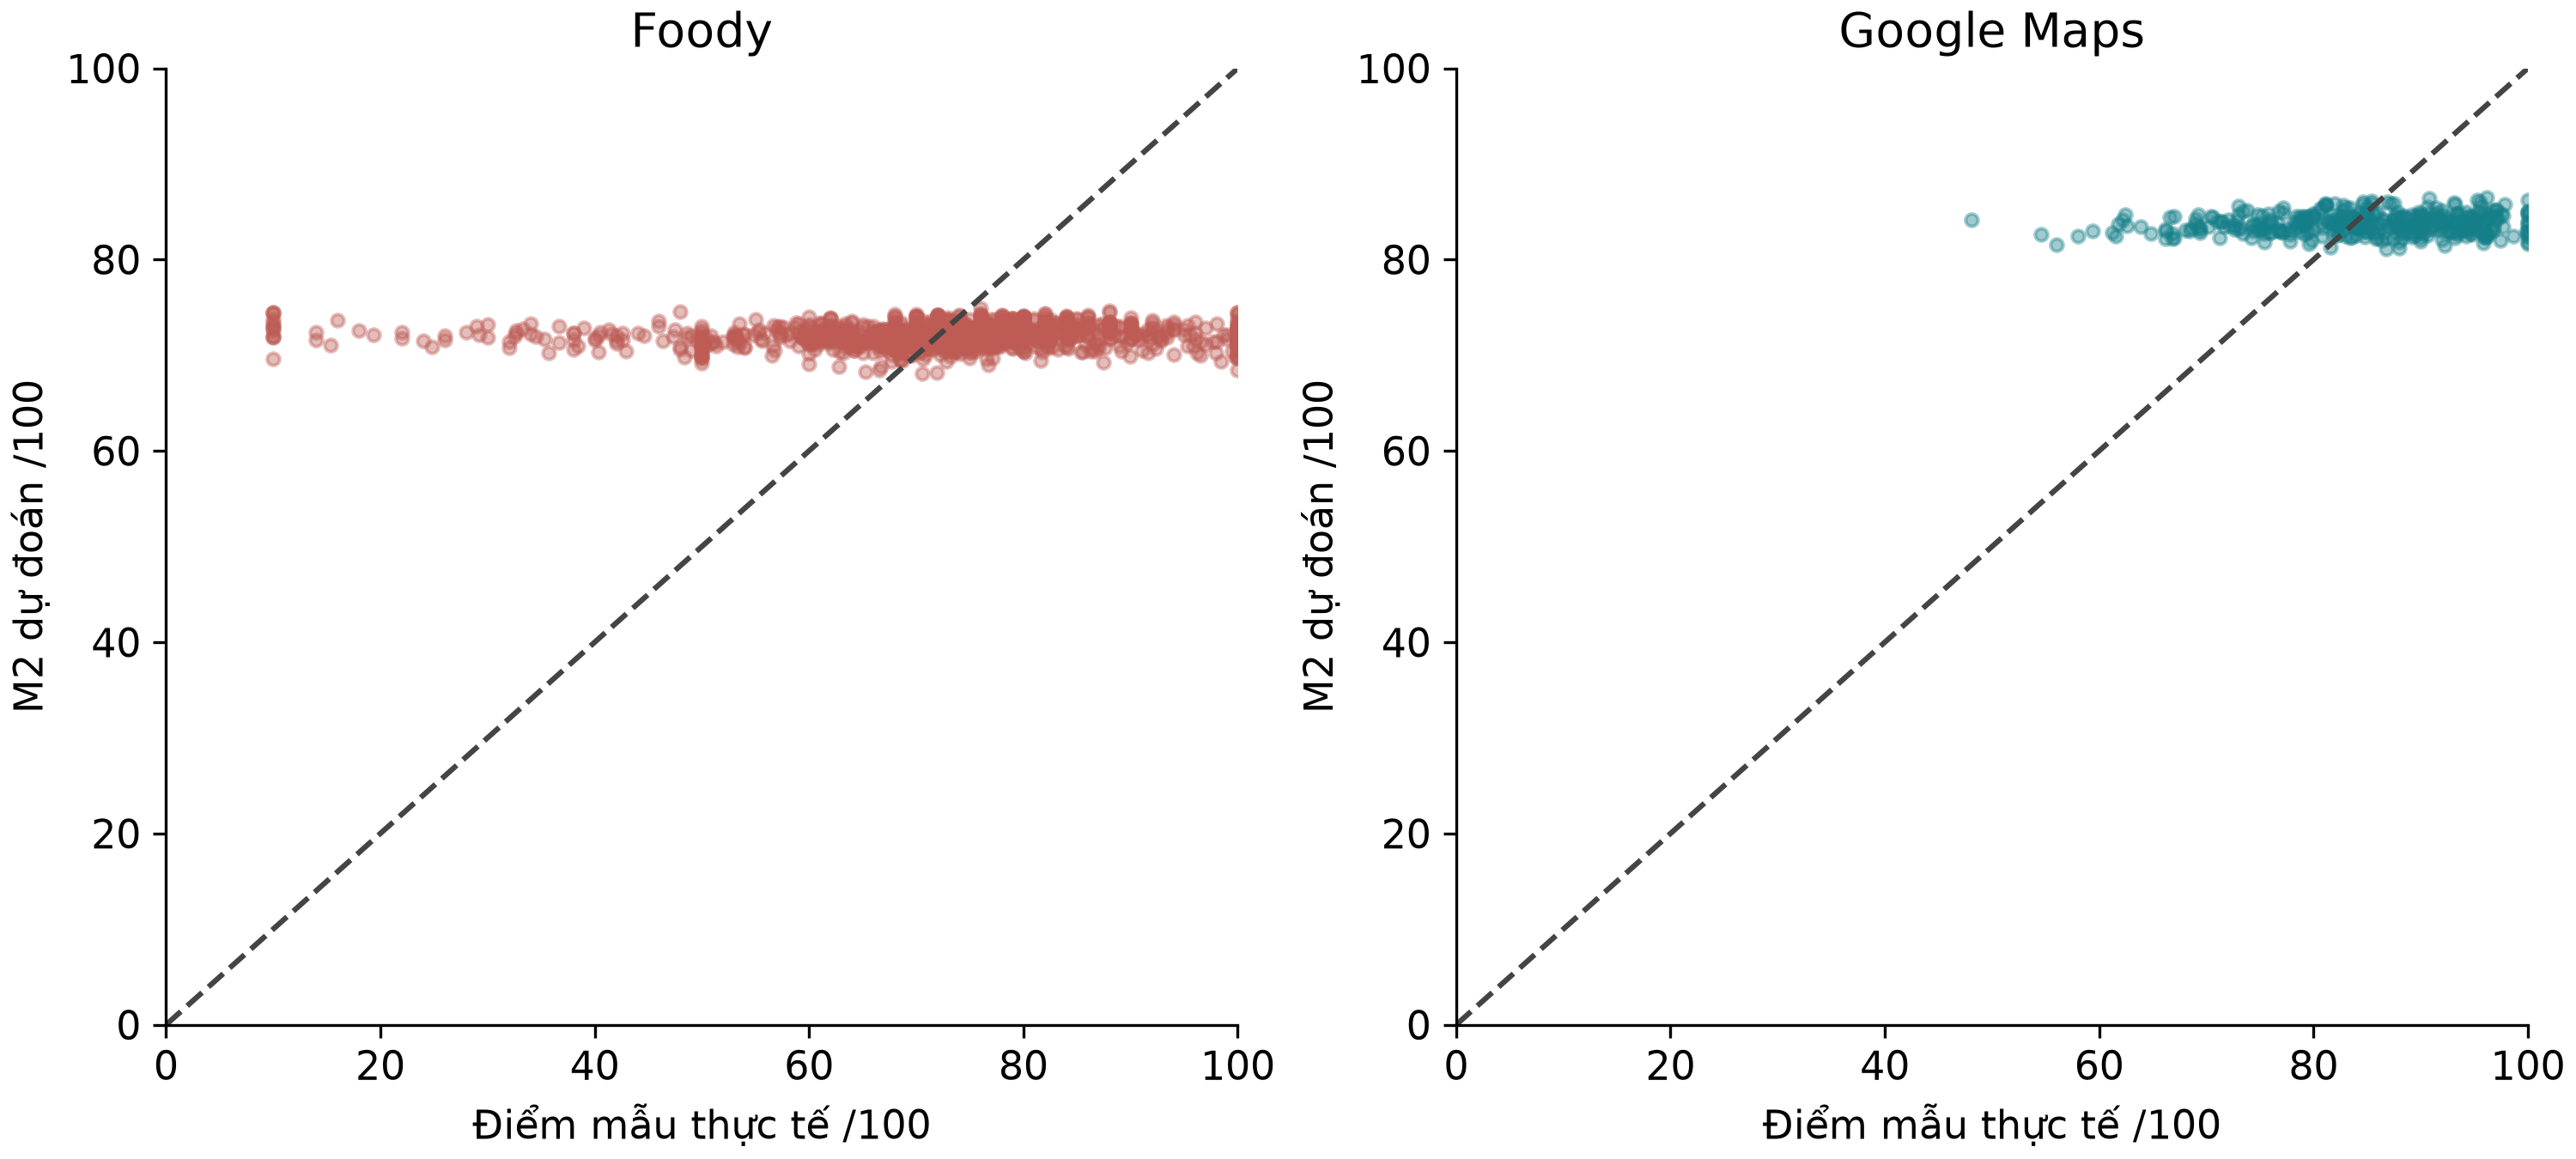

In [7]:
display(Image(filename=str(OUT/'fig3_test_rmse.png'),width=900))
display(Image(filename=str(OUT/'fig4_actual_vs_predicted.png'),width=900))

### Phần dư test
Thực tế trừ dự đoán; không nhận một đường ngang 0 là bằng chứng mô hình đúng. Xem cả độ phân tán, quán rating thấp và phân bố sai số.

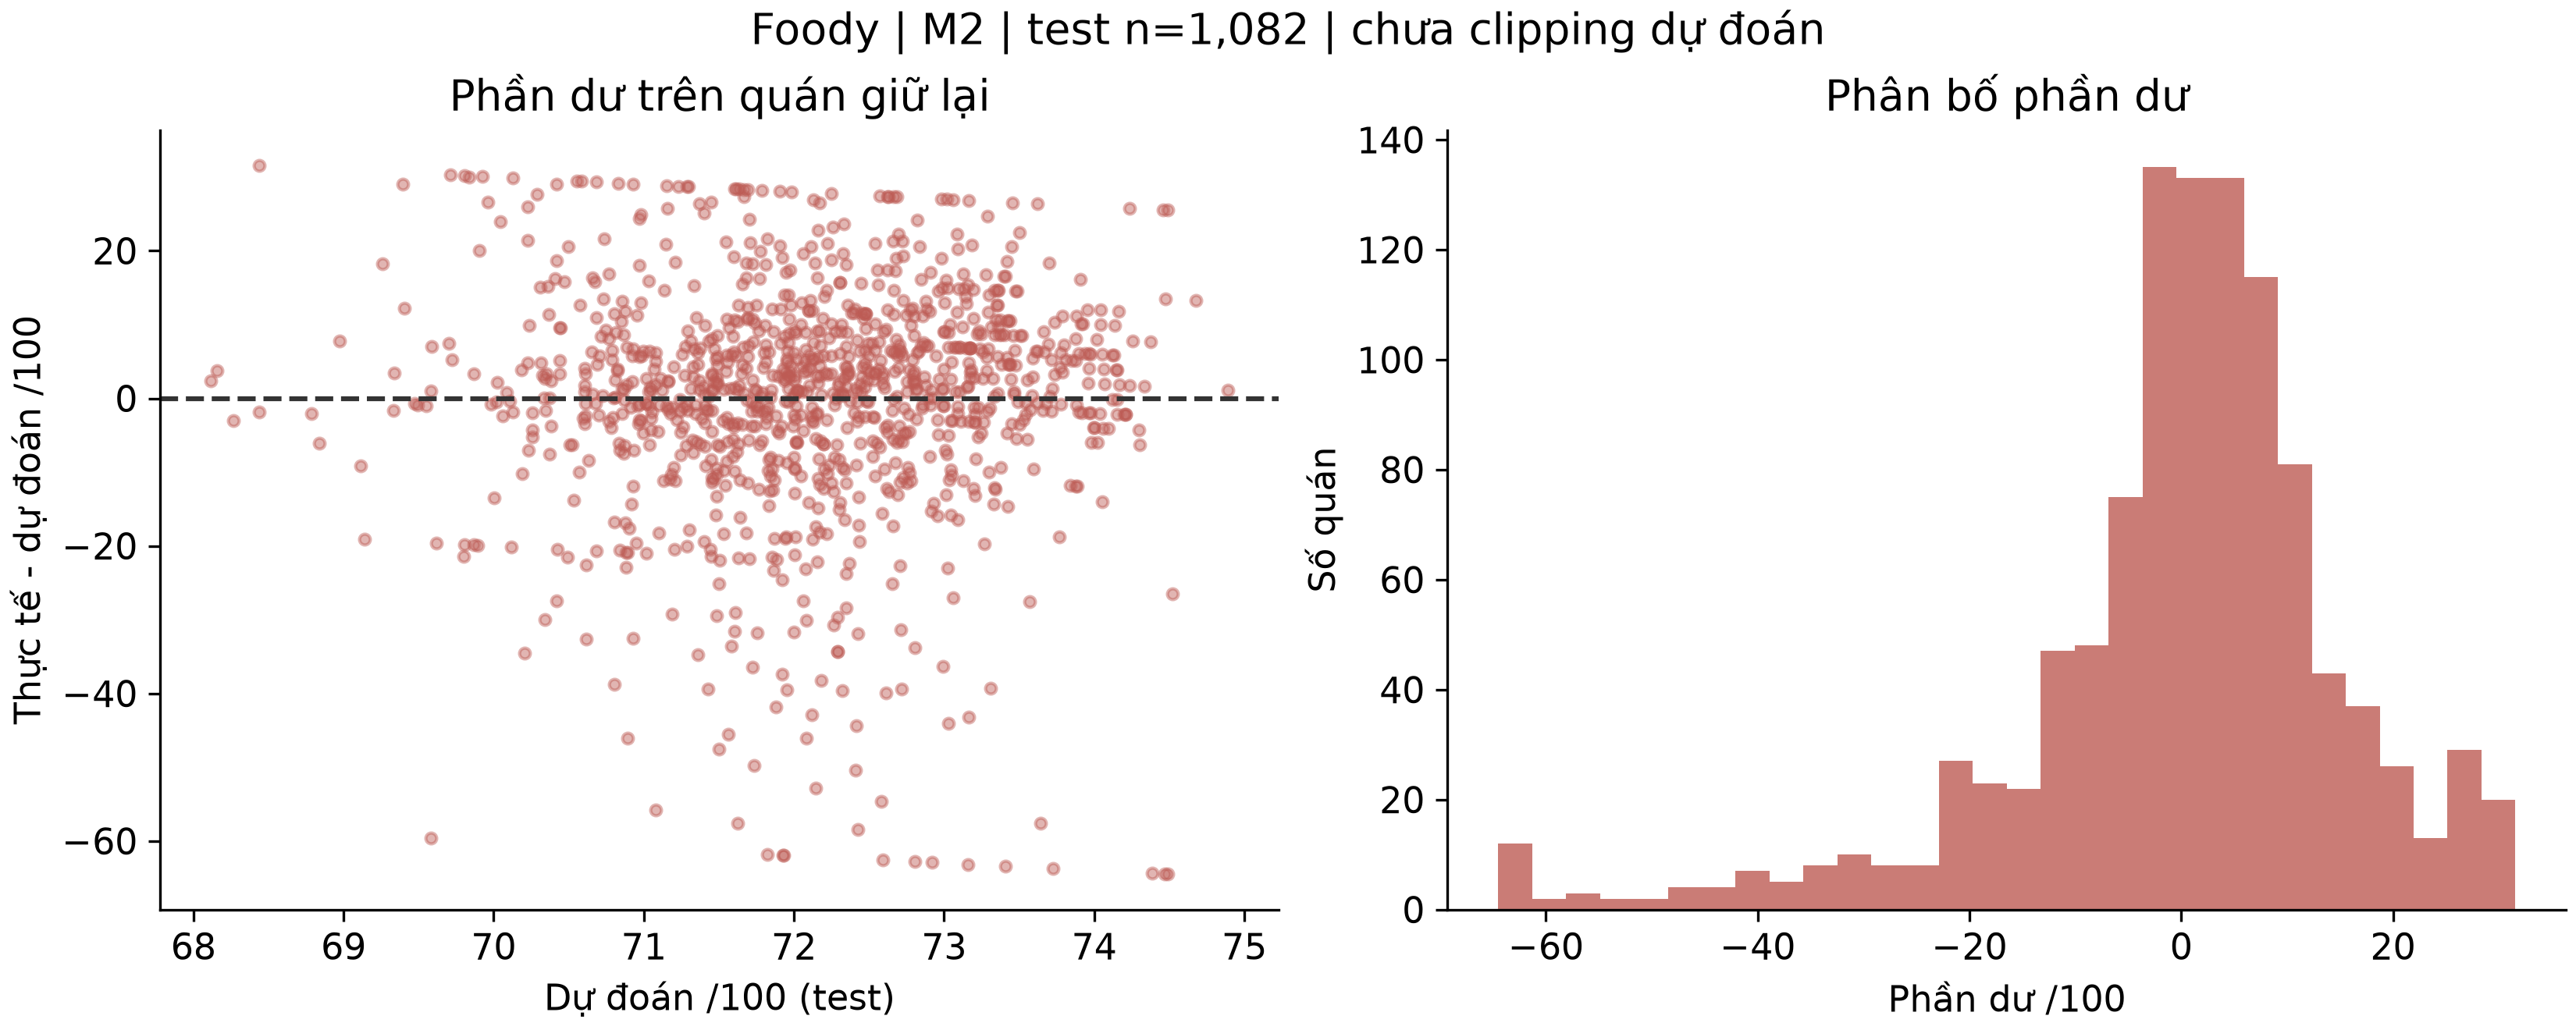

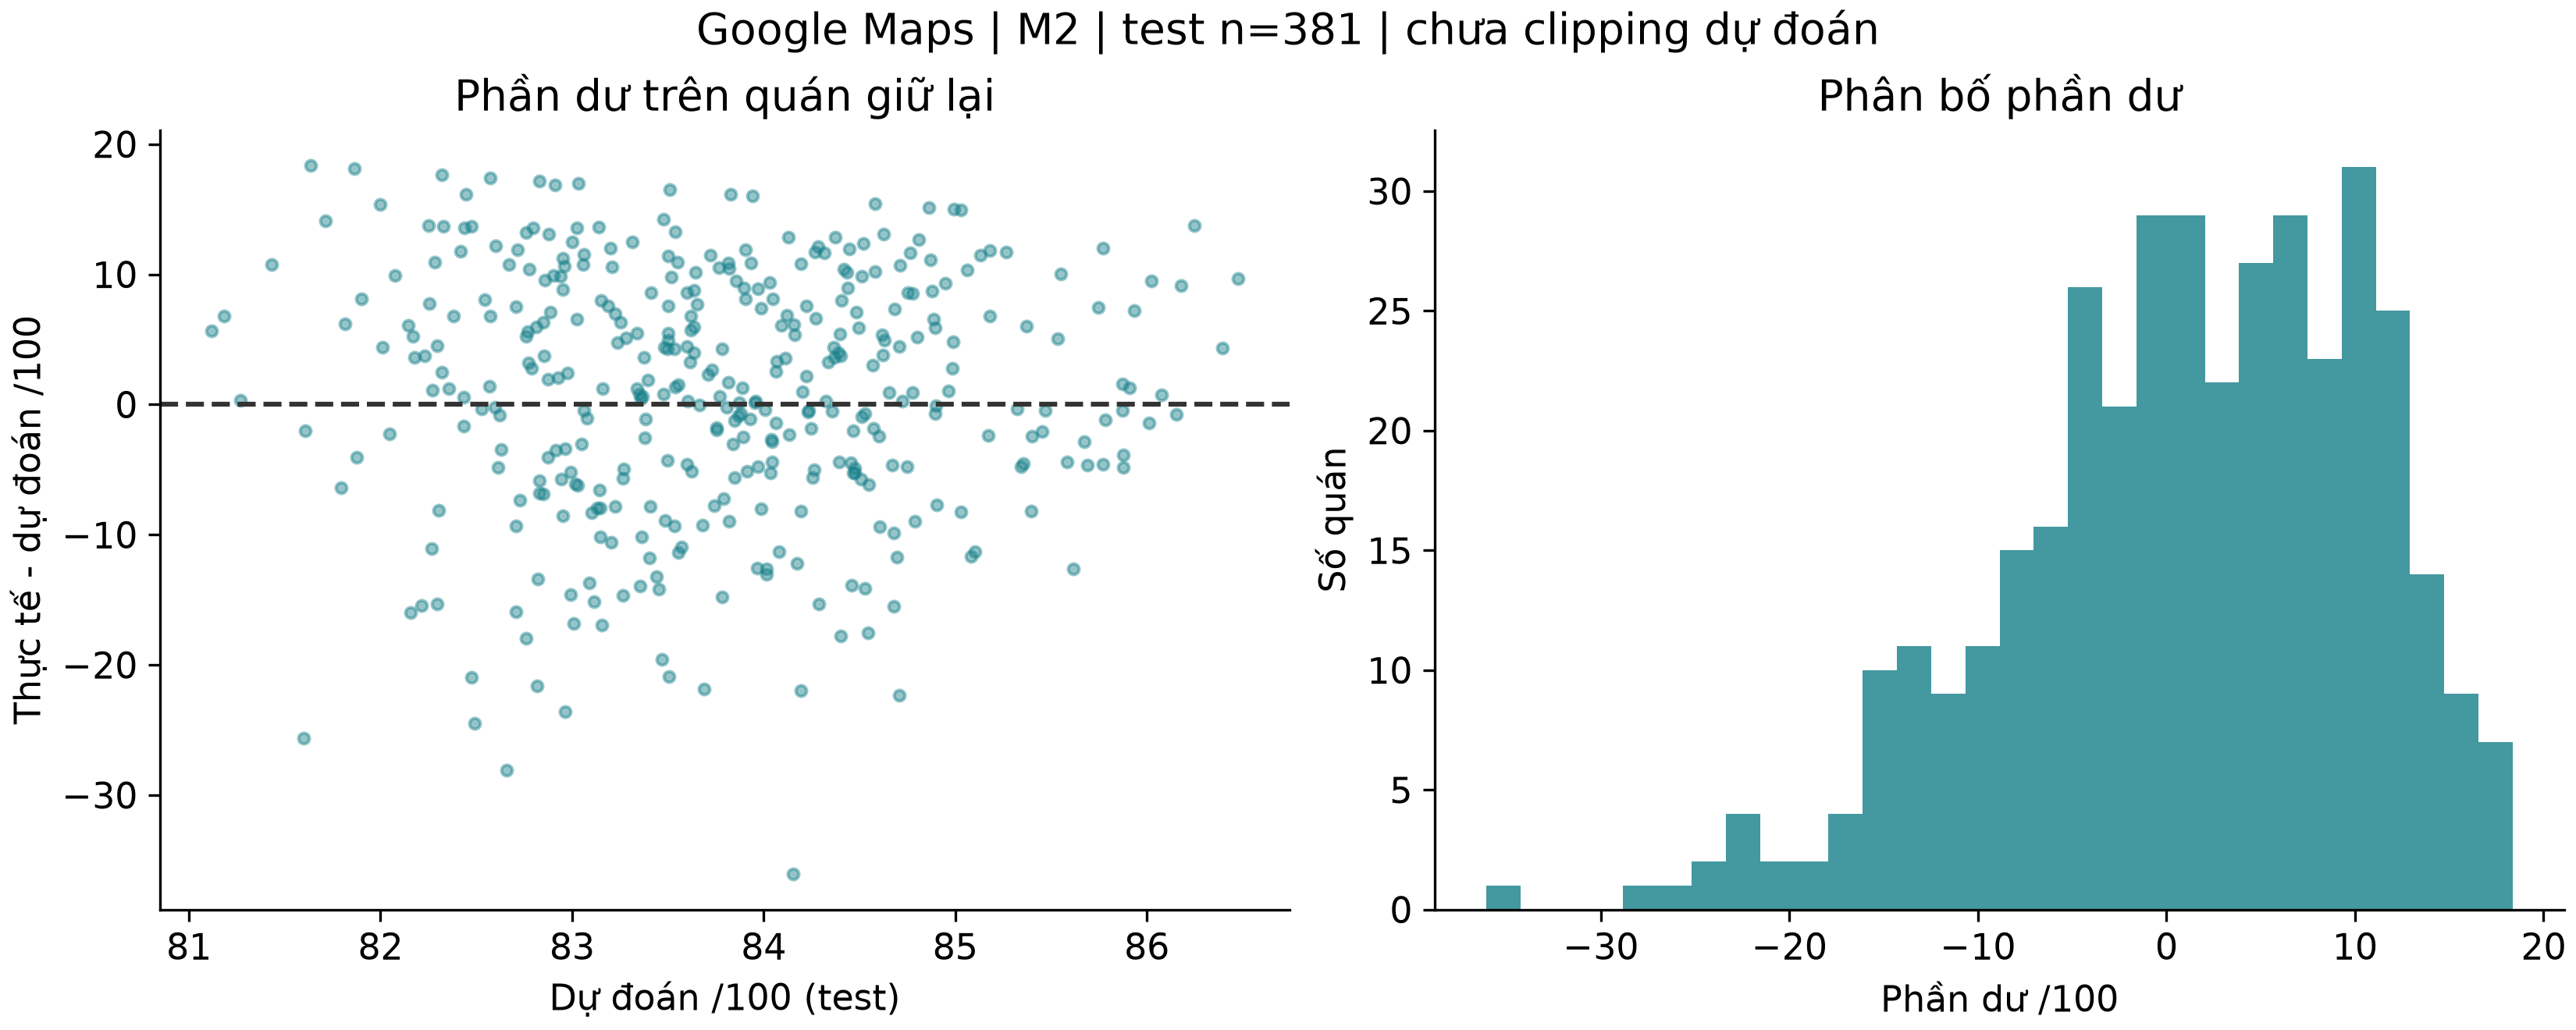

In [8]:
display(Image(filename=str(OUT/'fig1_residuals_foody.png'),width=900))
display(Image(filename=str(OUT/'fig1_residuals_google_maps.png'),width=900))

## 5. Hệ số, kiểm định và độ nhạy
Đọc dấu, độ lớn, CI và BH cùng nhau. Cùng dữ liệu EDA nên đây là kiểm tra mở rộng mang tính khám phá, chưa phải xác nhận trên snapshot độc lập.

,source,model,n,estimate,se,ci_low,ci_high,p
1,Foody,M1,5410,-0.958612,0.301651,-1.549970,-0.367255,0.001492
5,Foody,M2,5410,-1.066695,0.295149,-1.645307,-0.488083,0.000304
10,Foody,M3,5410,-1.513754,0.337103,-2.174612,-0.852896,0.000007
15,Google Maps,M1,1910,-1.330589,0.416762,-2.147946,-0.513232,0.001433
19,Google Maps,M2,1901,-1.119228,0.477955,-2.056600,-0.181855,0.019299


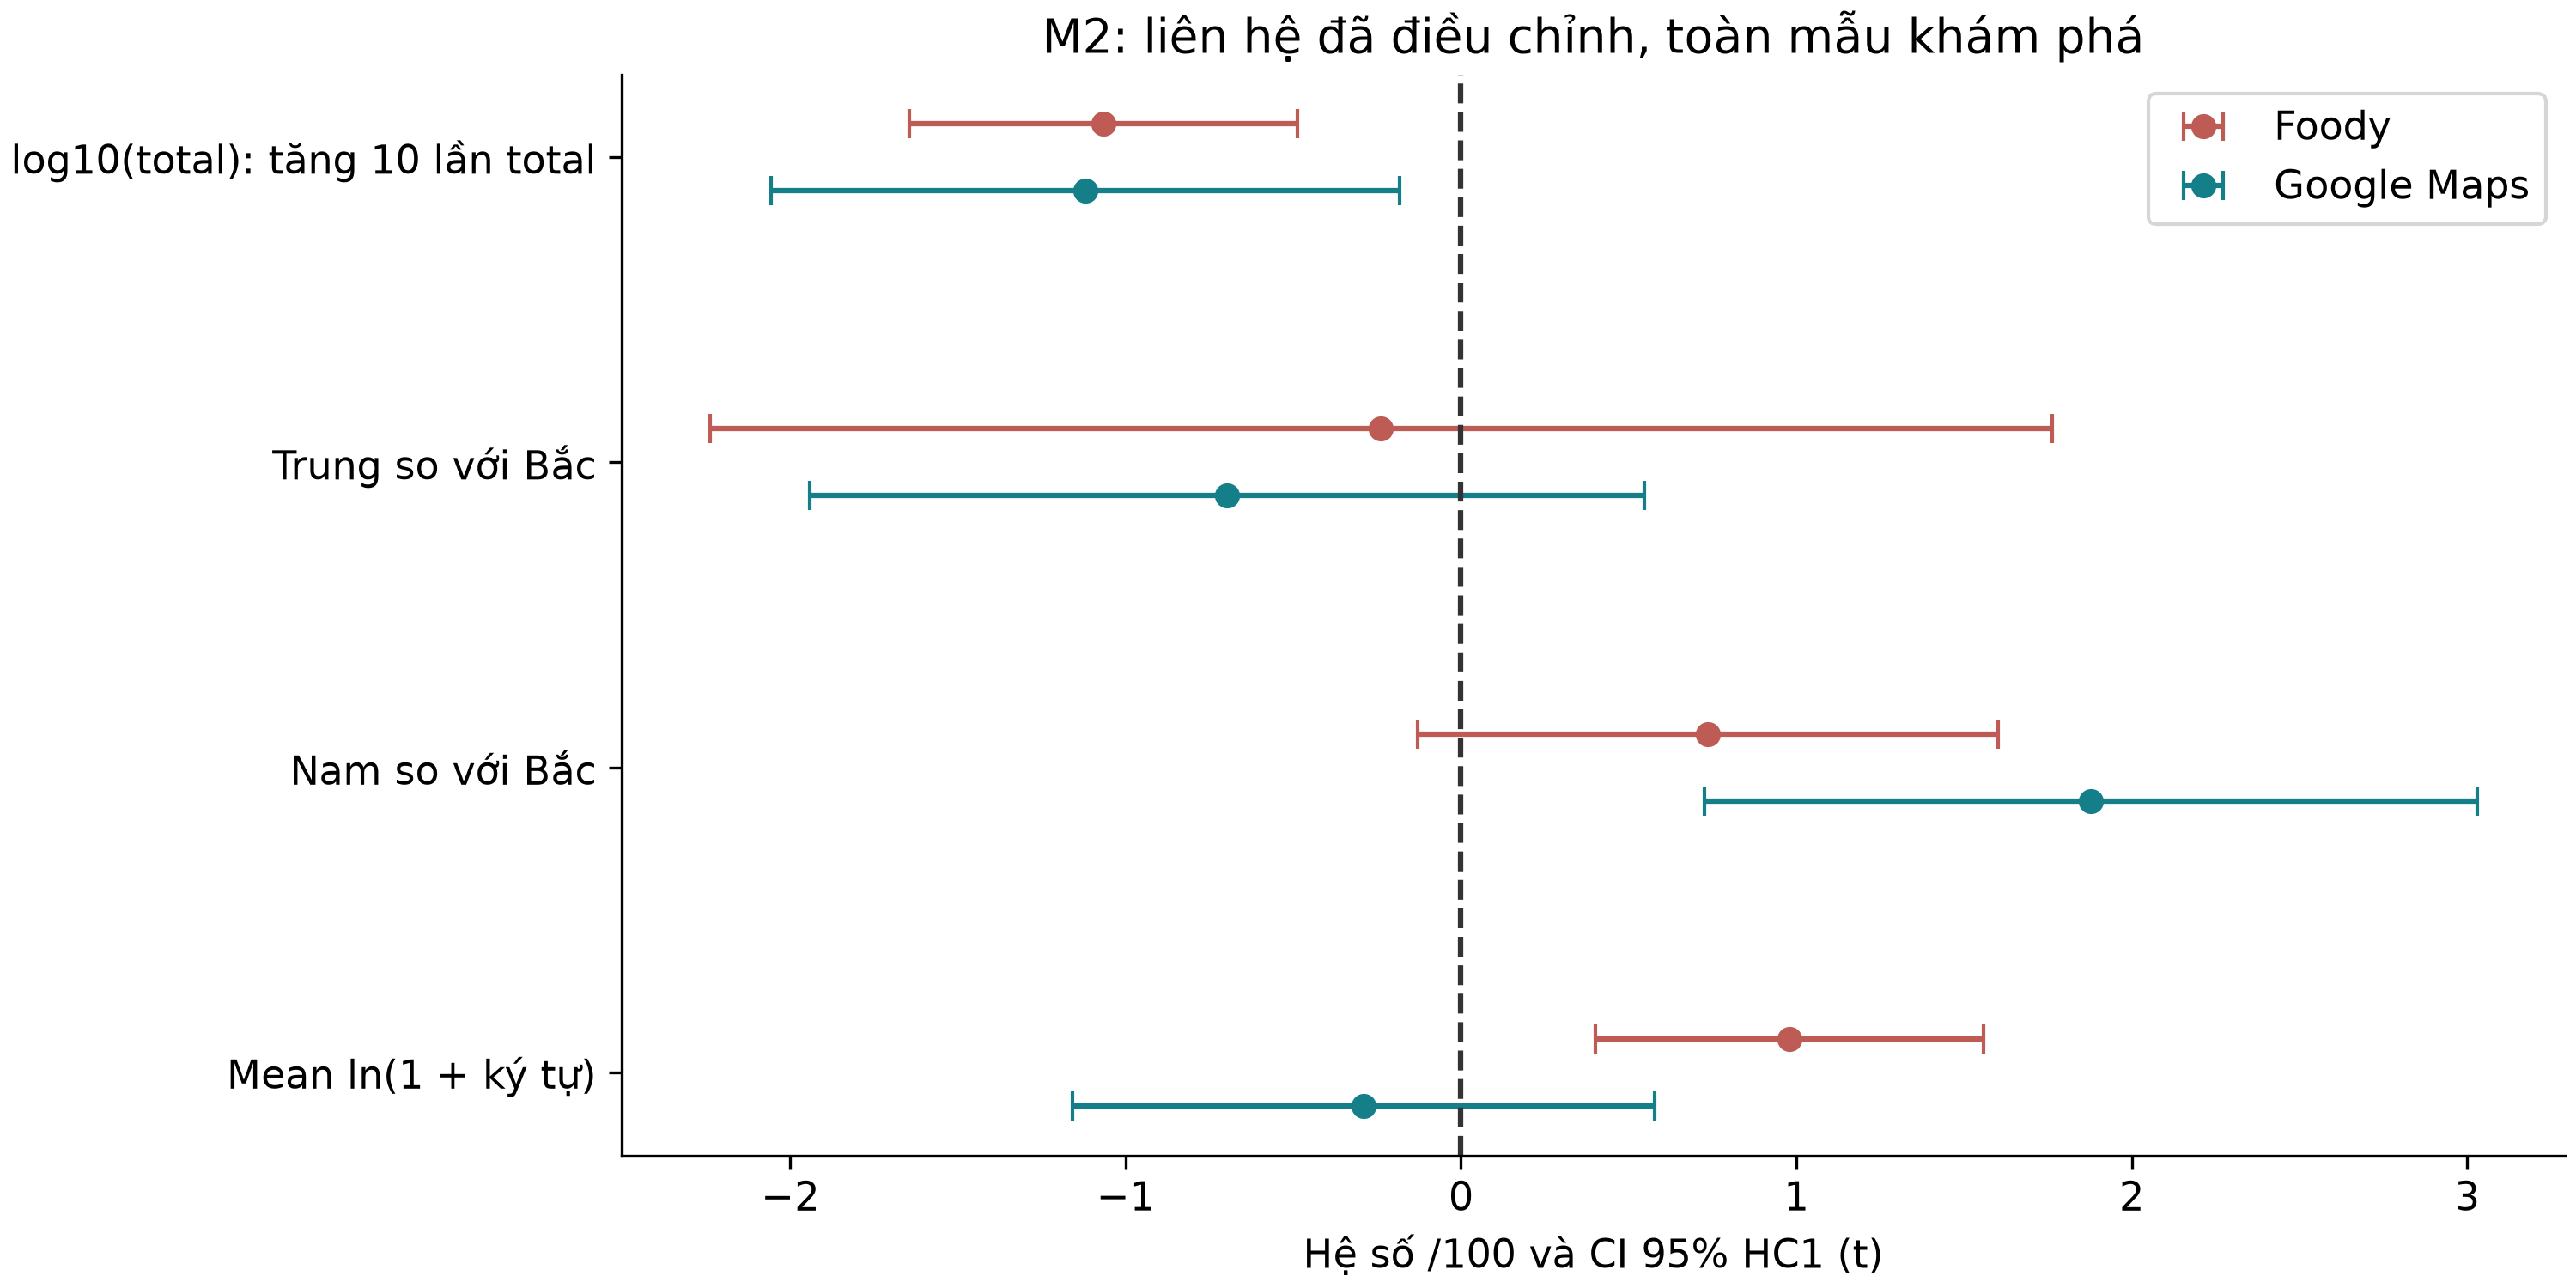

,source,model,hypothesis,f,df_num,df_denom,p
0,Foody,M1,region_Trung = region_Nam = 0,1.452819,2.0,5406.0,0.234001
1,Foody,M2,region_Trung = region_Nam = 0,1.656791,2.0,5405.0,0.190847
2,Foody,M3,region_Trung = region_Nam = 0,0.925480,2.0,5405.0,0.396404
3,Google Maps,M1,region_Trung = region_Nam = 0,9.324146,2.0,1906.0,0.000093
4,Google Maps,M2,region_Trung = region_Nam = 0,8.779765,2.0,1896.0,0.000160


,source,model,test,p,p_bh,family_size
0,Foody,M1,log10_total,1.491899e-03,2.237848e-03,12
1,Foody,M2,log10_total,3.041512e-04,7.299629e-04,12
2,Foody,M2,mean_log_length,9.207635e-04,1.841527e-03,12
3,Foody,M3,log10_total,7.254179e-06,2.901672e-05,12
4,Foody,M3,mean_log_length,5.120153e-03,6.826871e-03,12
5,Google Maps,M1,log10_total,1.432545e-03,2.237848e-03,12
6,Google Maps,M2,log10_total,1.929904e-02,2.315885e-02,12
7,Google Maps,M2,mean_log_length,5.109787e-01,5.109787e-01,12
8,Foody,M4,log1p_text_chars_within,1.914655e-16,1.148793e-15,12
9,Google Maps,M4,log1p_text_chars_within,3.691183e-249,4.429419e-248,12


In [9]:
coeff=pd.read_csv(OUT/'table2_hypothesis_testing_coefficients.csv')
display(coeff.loc[coeff.term=='log10_total',['source','model','n','estimate','se','ci_low','ci_high','p']])
display(Image(filename=str(OUT/'fig2_forest_plot_m2_coefficients.png'),width=900))
display(pd.read_csv(OUT/'table4_region_joint_tests.csv'))
display(pd.read_csv(OUT/'hypothesis_family_bh.csv'))

In [10]:
display(pd.read_csv(OUT/'sensitivity_coefficients.csv')[['source','sample','n','estimate','ci_low','ci_high','p']])

,source,sample,n,estimate,ci_low,ci_high,p
0,Foody,Tất cả đủ biến,5410,-1.066695,-1.645307,-0.488083,3.041512e-04
1,Foody,≥20 rating mẫu,1367,-0.332736,-1.607358,0.941886,6.086658e-01
2,Foody,Coverage ≥50%,5359,-1.049707,-1.638212,-0.461202,4.747913e-04
3,Foody,Bỏ địa lý proxy,5410,-1.066695,-1.645307,-0.488083,3.041512e-04
4,Google Maps,Tất cả đủ biến,1901,-1.119228,-2.056600,-0.181855,1.929904e-02
5,Google Maps,≥20 rating mẫu,1647,0.624418,-0.482025,1.730861,2.684924e-01
6,Google Maps,Coverage ≥50%,848,-4.607990,-6.356509,-2.859471,2.885432e-07
7,Google Maps,Bỏ địa lý proxy,1620,-0.781338,-1.813102,0.250426,1.376431e-01


### M4 và phép tính 50 lên 100 ký tự
Không nhân b với 50: biến giải thích là ln(1+L), nên nhân với ln(101/51). Demeaning dùng cùng tập review cho cả hai trung bình.

In [11]:
within=pd.read_csv(OUT/'table3_within_shop_review_regression.csv')
display(within[['source','n','clusters','estimate','se','ci_low','ci_high','numerator','denominator','cluster_meat','delta_50_to_100']])
print('ln(101/51)=',np.log(101/51))

,source,n,clusters,estimate,se,ci_low,ci_high,numerator,denominator,cluster_meat,delta_50_to_100
0,Foody,132922,5410,1.284131,0.155586,0.979119,1.589142,116614.093719,90811.704165,1.995931e+08,0.877440
1,Google Maps,131020,1901,-5.009903,0.126993,-5.258963,-4.760843,-583420.778318,116453.510852,2.185919e+08,-3.423241


ln(101/51)= 0.6832948841169337


## 6. Tính lại bảng metrics bằng dự đoán từng quán
Lấy phần dư rồi tính MSE/RMSE/MAE/R², không dựa vào bảng đã định dạng.

In [12]:
pred=pd.read_csv(OUT/'predictions.csv')
d=pred.loc[(pred.source=='Google Maps')&(pred.model=='M1')&(pred.partition=='test')]
recalculated=r.metrics(d.actual,d.predicted)
reported=evaluation.loc[(evaluation.source=='Google Maps')&(evaluation.model=='M1')&(evaluation.partition=='test')].iloc[0]
for key,value in recalculated.items(): assert np.isclose(value,reported[key])
display(pd.DataFrame([recalculated]))
plan=pd.read_csv(OUT/'split_assignments.csv')
assert plan.loc[plan.partition=='test','cv_fold'].isna().all()
print('Test never in CV:',True)

,mse,rmse,mae,r2
0,91.11398,9.545364,7.734822,0.002389


Test never in CV: True


## 7. Kiểm tra tái lập với lần chạy báo cáo
So từng bảng số của lần chạy mới với bản dùng trong báo cáo, bỏ thông tin thời gian và đường dẫn. Giữ seed và môi trường không đổi.

In [13]:
BASE=ROOT/'report4_outputs/20261115'
for filename in ['table1_model_evaluation_metrics.csv','table2_hypothesis_testing_coefficients.csv','table3_within_shop_review_regression.csv','split_assignments.csv','predictions.csv']:
    pd.testing.assert_frame_equal(pd.read_csv(OUT/filename),pd.read_csv(BASE/filename))
print('Identical metrics, coefficients, split assignments and predictions.')

Identical metrics, coefficients, split assignments and predictions.


## Kết luận
- M2 không tự động tốt hơn M1: phải đọc test và mốc Dummy.
- Mẫu ≥20 rating không giữ được liên hệ âm rõ ở cả hai nguồn.
- M4 cho liên hệ độ dài-rating khác dấu giữa hai nền tảng; không là tác động nhân quả.
- Classification là nhánh khác. Snapshot hiện tại chưa có gold train/validation/test; không bịa F1 hay accuracy từ rating.
- Xem `reports/report4/20261115/Report_4_Modeling.html` và `README_REPORT4.md` để bảo vệ kết quả.